In [1]:
!pip install -q pystac_client
!pip install -q planetary_computer

In [2]:
from pystac_client import Client
import planetary_computer

In [3]:
catalog = Client.open(
    'https://planetarycomputer.microsoft.com/api/stac/v1',
    modifier = planetary_computer.sign_inplace
)

In [4]:
roi = [45.912639, 36.889306, 46.221534, 37.105474]

In [5]:
search = catalog.search(
    collections = ['modis-11A2-061'],
    datetime = '2001/2025',
    bbox =roi
)

In [6]:
items = search.item_collection()

In [7]:
len(items)

2204

In [9]:
list(items[0].assets.keys())

['hdf',
 'QC_Day',
 'Emis_31',
 'Emis_32',
 'QC_Night',
 'tilejson',
 'LST_Day_1km',
 'Day_view_angl',
 'Day_view_time',
 'LST_Night_1km',
 'Clear_sky_days',
 'Night_view_angl',
 'Night_view_time',
 'Clear_sky_nights',
 'rendered_preview']

In [10]:
!pip install -q stackstac
from stackstac import stack

In [15]:
items_stack = stack(
    items,
    assets = ['QC_Day','LST_Day_1km'],
    bounds_latlon = roi,
    resolution = 1000,
    epsg = 3857
)

items_stack = items_stack.assign_coords(
    time = pd.to_datetime(items_stack['start_datetime'].values,
    utc = True).tz_localize(None)
).sortby('time')

In [13]:
import pandas as pd

In [19]:
ds =(
    items_stack.to_dataset('band')
    .drop_dims('band')
    .drop_attrs()
    .reset_coords(drop = True)
)

In [21]:
# 2 ** 0 = 1
# 2 ** 1 = 2
# 1 + 2 = 3

In [22]:
mask = ds['QC_Day'].astype(int) & 3
mask = (mask == 0).astype(int)
ds_mask = ds['LST_Day_1km'].where(mask)

In [24]:
temp_monthly = ds_mask.resample(time = 'M').mean('time')

/usr/local/lib/python3.13/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(


In [26]:
from dask.diagnostics import ProgressBar

In [28]:
import warnings
warnings.filterwarnings('ignore', category = RuntimeWarning)
import logging
logging.getLogger().setLevel(logging.ERROR)

In [29]:
with ProgressBar():
  temp_montly = temp_monthly.compute()

[########################################] | 100% Completed | 16m 23s


In [36]:
ds_smooth = temp_montly.rolling(
    time = 3,
    min_periods =1,
    center = True
).mean('time')

In [40]:
ds_mean = ds_smooth.mean(dim = 'time') - 273.15

In [44]:
temp_min = ds_smooth.groupby('time.month').min('time')
temp_min =  temp_min.sel(month = ds_smooth.time.dt.month)
temp_min

<xarray.DataArray 'LST_Day_1km' (time: 300, y: 31, x: 36)> Size: 3MB
array([[[275.76      , 277.39833333, 276.98877778, ..., 275.3       ,
         275.3       , 277.12088889],
        [277.22133333, 277.22133333, 276.35888889, ..., 275.58666667,
         277.005     , 275.91555556],
        [276.94349206, 276.25777778, 277.60539683, ..., 277.36444444,
         274.78333333, 277.44653968],
        ...,
        [274.92444444, 274.55733333, 274.91      , ..., 277.1       ,
         273.49      , 273.49      ],
        [272.65777778, 274.56833333, 274.63944444, ..., 277.00888889,
         276.96555556, 276.96555556],
        [272.665     , 272.98      , 272.98      , ..., 274.62833333,
         275.4425    , 274.515     ]],

       [[283.21833333, 283.05444444, 283.04266667, ..., 281.51666667,
         281.51666667, 282.89555556],
        [283.05822222, 283.05822222, 282.23933333, ..., 282.32833333,
         283.72166667, 282.26666667],
        [282.82215873, 282.27244444, 283.60895238, ..., 283.86444444,
         281.87555556, 284.06972222],
...
        [281.245     , 281.495     , 281.68833333, ..., 279.37      ,
         278.92      , 280.39      ],
        [281.8       , 281.9575    , 281.818     , ..., 278.01333333,
         280.345     , 280.345     ],
        [281.83      , 282.09      , 282.09      , ..., 280.324     ,
         279.41      , 279.46      ]],

       [[278.32666667, 278.28      , 278.55277778, ..., 278.22944444,
         278.22944444, 277.656     ],
        [278.57466667, 278.57466667, 278.39733333, ..., 278.38066667,
         277.90722222, 278.15666667],
        [278.71266667, 278.612     , 279.22111111, ..., 278.75377778,
         278.81444444, 279.03622222],
        ...,
        [275.46      , 275.18166667, 275.62666667, ..., 277.13777778,
         276.69777778, 277.48      ],
        [275.66555556, 277.57555556, 276.37333333, ..., 277.62222222,
         276.28444444, 276.28444444],
        [274.58888889, 276.22222222, 276.22222222, ..., 277.42555556,
         275.92333333, 276.40666667]]], shape=(300, 31, 36))
Coordinates:
  * time     (time) datetime64[ns] 2kB 2001-01-31 2001-02-28 ... 2025-12-31
  * y        (y) float64 248B 4.454e+06 4.453e+06 ... 4.425e+06 4.424e+06
  * x        (x) float64 288B 5.11e+06 5.111e+06 ... 5.144e+06 5.145e+06
    month    (time) int64 2kB 1 2 3 4 5 6 7 8 9 10 11 ... 3 4 5 6 7 8 9 10 11 12

In [45]:
temp_max = ds_smooth.groupby('time.month').max('time')
temp_max = temp_max.sel(month = ds_smooth.time.dt.month)
temp_max

<xarray.DataArray 'LST_Day_1km' (time: 300, y: 31, x: 36)> Size: 3MB
array([[[286.81644444, 288.18      , 287.57333333, ..., 288.03595238,
         288.03595238, 287.35083333],
        [285.68333333, 285.68333333, 288.16      , ..., 288.33857143,
         287.68714286, 287.47166667],
        [285.78      , 287.59      , 285.804     , ..., 288.57190476,
         288.11458333, 288.07125   ],
        ...,
        [288.21857143, 288.87964286, 289.50380952, ..., 286.58933333,
         286.51555556, 286.7275    ],
        [287.9945    , 288.58914286, 288.115     , ..., 287.8047619 ,
         287.48666667, 287.48666667],
        [289.1375    , 289.17      , 289.17      , ..., 286.935     ,
         286.785     , 288.435     ]],

       [[292.055     , 293.8275    , 300.105     , ..., 293.88566667,
         293.88566667, 296.68      ],
        [298.035     , 298.035     , 293.29      , ..., 293.684     ,
         293.26714286, 292.635     ],
        [290.01166667, 291.05433333, 290.68746032, ..., 293.235     ,
         293.81333333, 294.23666667],
...
        [296.93611111, 297.67785714, 298.01047619, ..., 297.315     ,
         296.85333333, 297.55833333],
        [296.90416667, 297.15416667, 297.64083333, ..., 296.33916667,
         296.518     , 296.518     ],
        [296.59107143, 297.03575397, 297.03575397, ..., 293.97555556,
         297.303     , 296.942     ]],

       [[286.95222222, 288.46644444, 288.58933333, ..., 288.25285714,
         288.25285714, 287.5925    ],
        [286.56555556, 286.56555556, 288.13206349, ..., 289.39190476,
         288.18339286, 287.80875   ],
        [286.20955556, 287.19555556, 289.07666667, ..., 289.78142857,
         289.03696429, 288.375     ],
        ...,
        [286.92116667, 287.494     , 289.06017857, ..., 287.51222222,
         288.06666667, 288.72277778],
        [287.1475    , 287.64333333, 287.7455    , ..., 294.06      ,
         294.32      , 294.32      ],
        [288.30464286, 288.70892857, 288.70892857, ..., 286.95777778,
         287.875     , 288.21      ]]], shape=(300, 31, 36))
Coordinates:
  * time     (time) datetime64[ns] 2kB 2001-01-31 2001-02-28 ... 2025-12-31
  * y        (y) float64 248B 4.454e+06 4.453e+06 ... 4.425e+06 4.424e+06
  * x        (x) float64 288B 5.11e+06 5.111e+06 ... 5.144e+06 5.145e+06
    month    (time) int64 2kB 1 2 3 4 5 6 7 8 9 10 11 ... 3 4 5 6 7 8 9 10 11 12

In [46]:
tci = (
    (temp_max - ds_smooth) / (temp_max - temp_min)
) * 100

In [51]:
tci_mean = tci.median(dim = ['x','y']).to_dataframe()['LST_Day_1km']

<Axes: xlabel='time'>

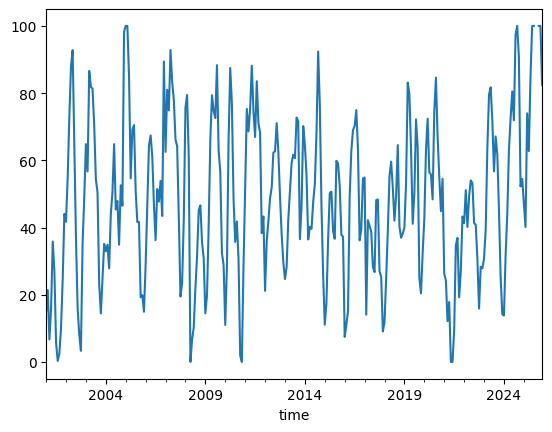

In [52]:
tci_mean.plot()